# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MbaliThusi/Mbali-Flyrank-intern-rep./blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


In [1]:
import pandas as pd, numpy as np
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])
print(df.shape)

Saving content_refresh_anonymized.csv to content_refresh_anonymized.csv
(30000, 44)


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


                          count     mean      50%       90%       99%  \
clicks_90d              30000.0    16.10     1.00     32.00    253.01   
impressions_90d         30000.0  5200.37   731.00  12136.40  73505.83   
search_volume           27532.0   158.88    10.00    110.00   2900.00   
word_count              22301.0  3107.76  2877.00   5327.00   7292.00   
content_age_days        30000.0   256.17   236.00    463.00    537.00   
days_since_last_update  30000.0    46.10    20.00    104.00    106.00   
avg_position            30000.0    16.34    10.80     36.80     69.90   
ctr                     30000.0     0.51     0.07      0.65      8.33   
trend_pct               26612.0    -4.79   -33.50     50.00    393.25   

                             max   skew  p99/median  
clicks_90d                4178.0  18.35       253.0  
impressions_90d         517715.0  11.38       100.6  
search_volume            74000.0  26.02       290.0  
word_count                9546.0   0.94         2.5  

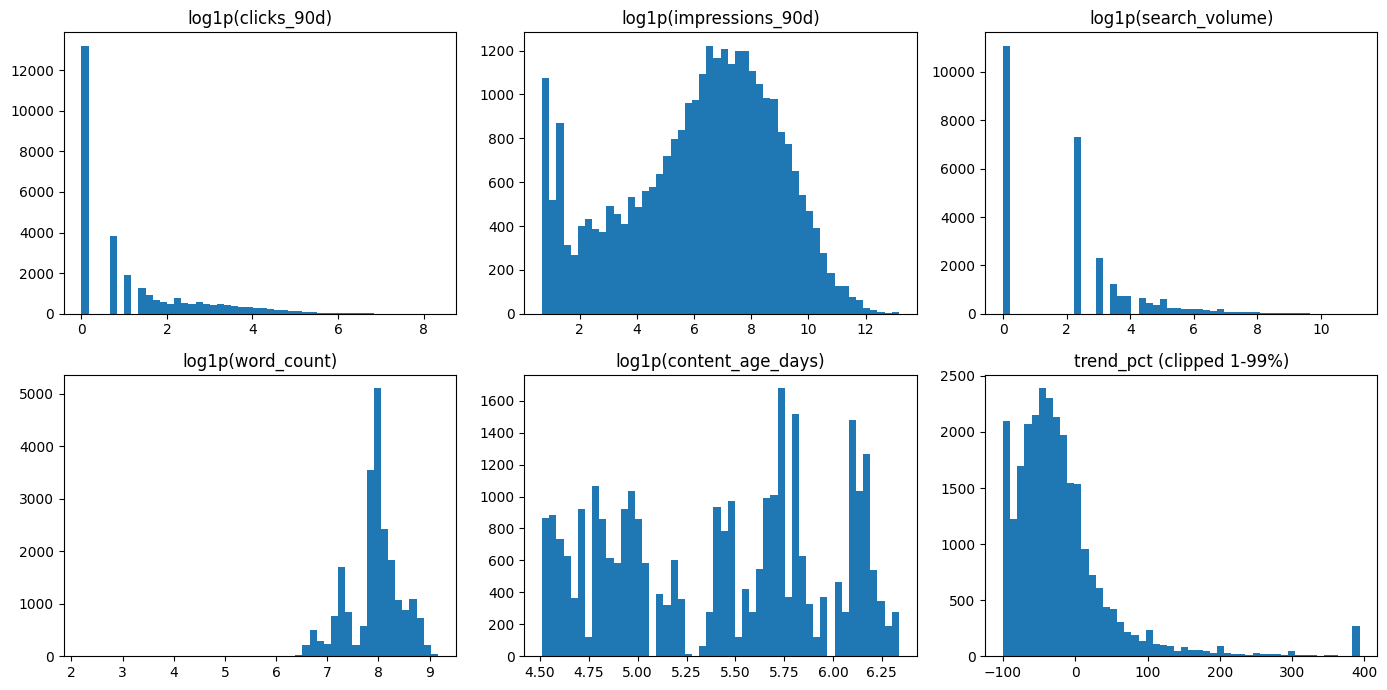

In [2]:
import matplotlib.pyplot as plt

key = ["clicks_90d", "impressions_90d", "search_volume", "word_count",
       "content_age_days", "days_since_last_update", "avg_position", "ctr", "trend_pct"]
d = df[key].replace([np.inf, -np.inf], np.nan)

summary = d.describe(percentiles=[.5, .9, .99]).T
summary["skew"] = d.skew()
summary["p99/median"] = (summary["99%"] / summary["50%"].replace(0, np.nan)).round(1)
print(summary[["count", "mean", "50%", "90%", "99%", "max", "skew", "p99/median"]].round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), ["clicks_90d", "impressions_90d", "search_volume",
                                "word_count", "content_age_days", "trend_pct"]):
    s = d[c].dropna()
    if s.min() >= 0:
        ax.hist(np.log1p(s), bins=50); ax.set_title(f"log1p({c})")
    else:
        ax.hist(s.clip(s.quantile(.01), s.quantile(.99)), bins=50); ax.set_title(f"{c} (clipped 1-99%)")
plt.tight_layout(); plt.show()

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


In [3]:
b = df[df["clicks_prev_30d"] > 0].copy()
b["declined"] = (b["clicks_last_30d"] < b["clicks_prev_30d"]).astype(int)

# Does the rule's assumption hold at several thresholds?
rows = []
for days in [90, 180, 270, 365]:
    flagged = b["days_since_last_update"] > days
    rows.append([days, flagged.sum(),
                 b.loc[flagged, "declined"].mean(),
                 b.loc[~flagged, "declined"].mean()])
res = pd.DataFrame(rows, columns=["stale_after_days", "n_flagged", "decline_rate_flagged", "decline_rate_not_flagged"])
res["lift"] = res["decline_rate_flagged"] - res["decline_rate_not_flagged"]
print(res.round(3).to_string(index=False))

# Does it hold inside each client, or only pooled?
flagged = b["days_since_last_update"] > 180
by_client = b.assign(f=flagged).groupby(["client_id", "f"])["declined"].mean().unstack()
by_client = by_client.dropna()
print("clients where flagged declines MORE:", (by_client[True] > by_client[False]).mean().round(2))


 stale_after_days  n_flagged  decline_rate_flagged  decline_rate_not_flagged   lift
               90       4483                 0.561                     0.589 -0.028
              180         21                 0.762                     0.578  0.183
              270          1                 0.000                     0.579 -0.579
              365          0                   NaN                     0.579    NaN
clients where flagged declines MORE: 0.5


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


“Of the three signals, [X] is confirmed and [Y] is not, so the team should [action]. The staleness flag [holds / only partly holds], so [use it as a first filter / don’t trust it alone]. Because the data has heavy tails, judge by medians and ranks, not averages.”

Before you submit


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.